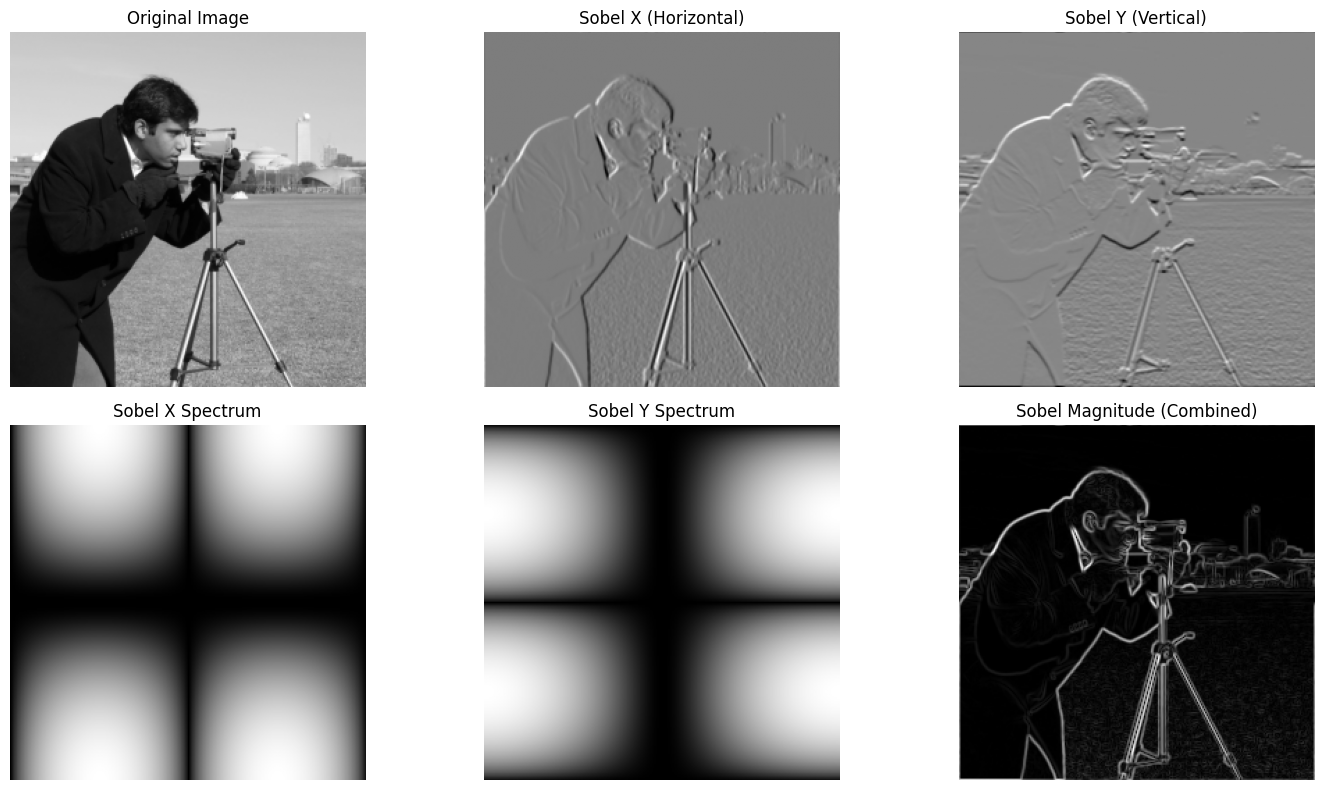

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from scipy.fft import fft2, ifftshift, ifft2

# 1. Load and resize image
image = data.camera()
image = resize(image, (256, 256))  # Match size from earlier step
M, N = image.shape

# 2. Define Sobel kernels
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# 3. Kernel padding and embedding function
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2 : cy - kh//2 + kh, cx - kw//2 : cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# 4. Compute FFT of the image and the filters
F_img = fft2(image)
H_x = center_embed_kernel(sobel_x, (M, N))
H_y = center_embed_kernel(sobel_y, (M, N))

# 5. Multiply in frequency domain
G_x = F_img * H_x
G_y = F_img * H_y

# 6. Inverse FFT to get spatial domain results
g_x = ifft2(G_x).real
g_y = ifft2(G_y).real

# Compute magnitude representation of gradients
sobel_magnitude = np.sqrt(g_x**2 + g_y**2)

# 7. Plotting the results
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(g_x, cmap='gray')
plt.title('Sobel X (Horizontal)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(g_y, cmap='gray')
plt.title('Sobel Y (Vertical)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(np.log(1 + np.abs(H_x)), cmap='gray')
plt.title('Sobel X Spectrum')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(np.log(1 + np.abs(H_y)), cmap='gray')
plt.title('Sobel Y Spectrum')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Magnitude (Combined)')
plt.axis('off')

plt.tight_layout()
plt.show()